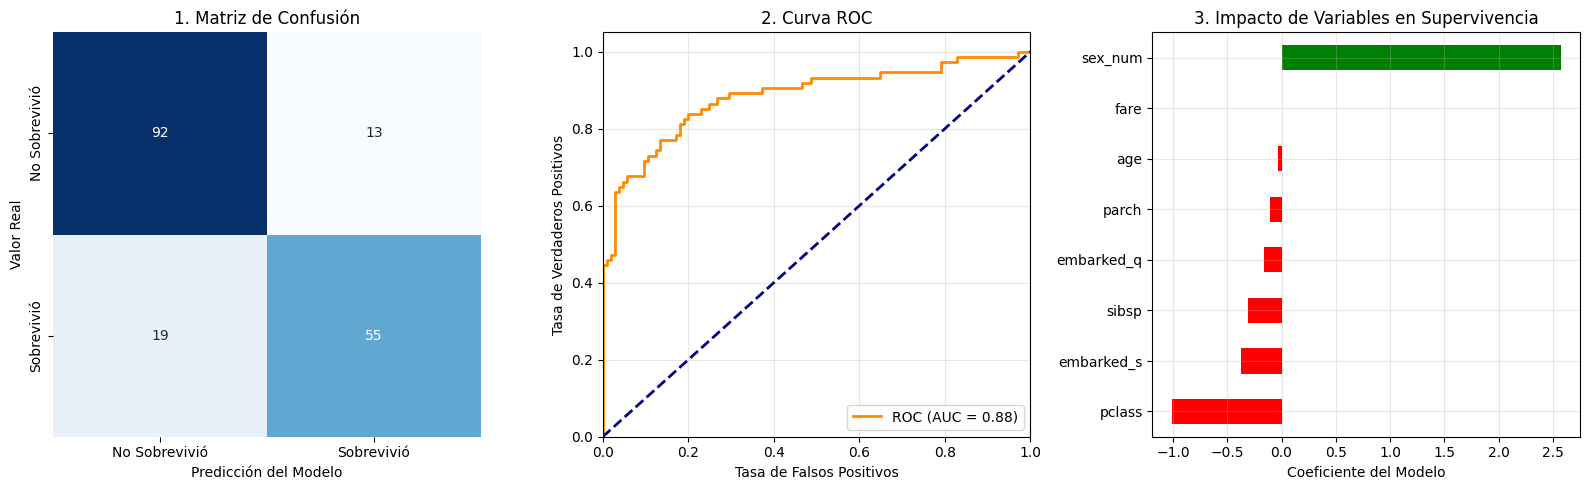

Precisión global del modelo (Accuracy): 82.12%


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, auc

# 1. Cargar el archivo limpio
df = pd.read_csv('titanic_limpio.csv')

# 2. Definir variables predictoras y objetivo
features = ['pclass', 'age', 'sibsp', 'parch', 'fare', 'sex_num', 'embarked_q', 'embarked_s']
X = df[features]
y = df['survived']

# 3. Dividir datos en Entrenamiento (80%) y Prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Entrenar la Regresión Logística
modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_train, y_train)

# 5. Predecir valores y probabilidades
y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

# ==========================================
# GENERACIÓN DE GRÁFICAS DEL MODELO
# ==========================================
plt.figure(figsize=(16, 5))

# Gráfica 1: Matriz de Confusión
plt.subplot(1, 3, 1)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Sobrevivió', 'Sobrevivió'],
            yticklabels=['No Sobrevivió', 'Sobrevivió'])
plt.title('1. Matriz de Confusión')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')

# Gráfica 2: Curva ROC (Evaluación de rendimiento)
plt.subplot(1, 3, 2)
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('2. Curva ROC')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

# Gráfica 3: Importancia de cada Variable
plt.subplot(1, 3, 3)
coeficientes = pd.Series(modelo.coef_[0], index=features).sort_values()
coeficientes.plot(kind='barh', color=['red' if x < 0 else 'green' for x in coeficientes])
plt.title('3. Impacto de Variables en Supervivencia')
plt.xlabel('Coeficiente del Modelo')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Precisión global del modelo (Accuracy): {accuracy_score(y_test, y_pred) * 100:.2f}%")